# 원본 Process 행 모델 — 최신 결과

완료된 Process 실행 행을 유지하고 과거 맥락을 파생변수로 추가합니다. IF·K-means·LOF 각각 하나의 공유 모델입니다. 아래 주 성능은 통계 보정과 경보 유지가 포함된 **최종 분 단위 경보**의 결과입니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'model_manifest.json').is_file())
read=lambda p: json.loads((ROOT/p).read_text(encoding='utf-8'))
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
NAMES={'if':'Isolation Forest','kmeans':'MiniBatch K-means','lof':'LOF'}
KEYS=['accuracy','precision','recall','f1']


## 1. 최신 전체 성능

개별 지연·집단 지연·시간대 폭주·점진적 악화의 확인 사례 집계입니다. 입력 중단은 제외했습니다. 합성 벤치마크 반복 연구 결과이며 외부 블라인드 검증은 아닙니다.

,Model,accuracy,precision,recall,f1,FPR
0,Isolation Forest,94.28,90.98,75.10,82.28,1.60
1,MiniBatch K-means,94.20,90.64,74.89,82.02,1.66
2,LOF,94.15,87.02,78.61,82.60,2.52


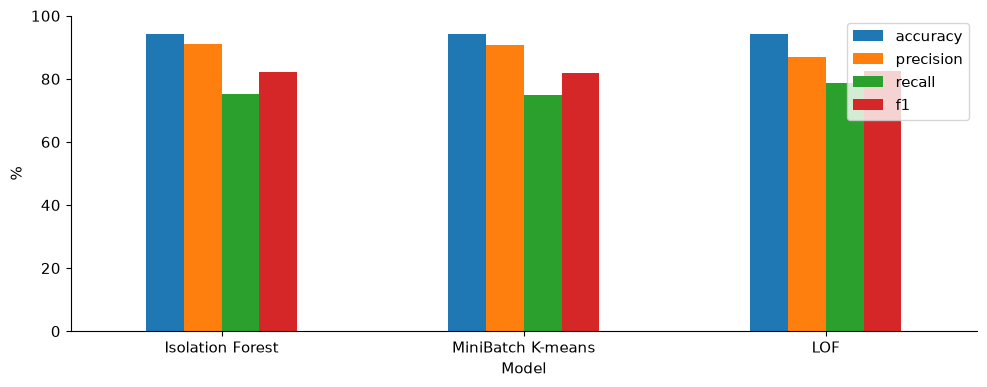

In [2]:
report=read('results/latest/minute_confirmation.json')
table=pd.DataFrame([{'Model':NAMES[a],**{k:100*r[k] for k in KEYS},'FPR':100*r['false_positive_rate']} for a,r in report['pooled'].items()])
display(table.round(2))
table.set_index('Model')[KEYS].plot.bar(figsize=(10,4),rot=0,ylim=(0,100));plt.ylabel('%');plt.tight_layout();plt.show()


## 2. 시나리오별 최신 성능

같은 확인 사례 4,600개/시나리오와 대응 정상 대조군입니다. FPR은 정상 분을 이상으로 표시한 비율입니다.

,Task,Model,accuracy,precision,recall,f1,FPR
0,individual_delay,Isolation Forest,98.42,98.52,82.63,89.88,0.11
1,individual_delay,MiniBatch K-means,97.75,98.51,74.60,84.90,0.10
2,individual_delay,LOF,97.76,98.05,75.13,85.08,0.14
3,group_delay,Isolation Forest,97.99,91.55,95.56,93.51,1.57
4,group_delay,MiniBatch K-means,97.88,91.00,95.45,93.17,1.69
5,group_delay,LOF,96.76,85.72,94.33,89.82,2.81
6,time_burst,Isolation Forest,94.02,78.34,59.11,67.38,1.91
7,time_burst,MiniBatch K-means,94.08,79.35,58.62,67.43,1.78
8,time_burst,LOF,93.68,75.98,57.83,65.67,2.13
9,gradual_degradation,Isolation Forest,91.81,93.88,71.77,81.35,1.55


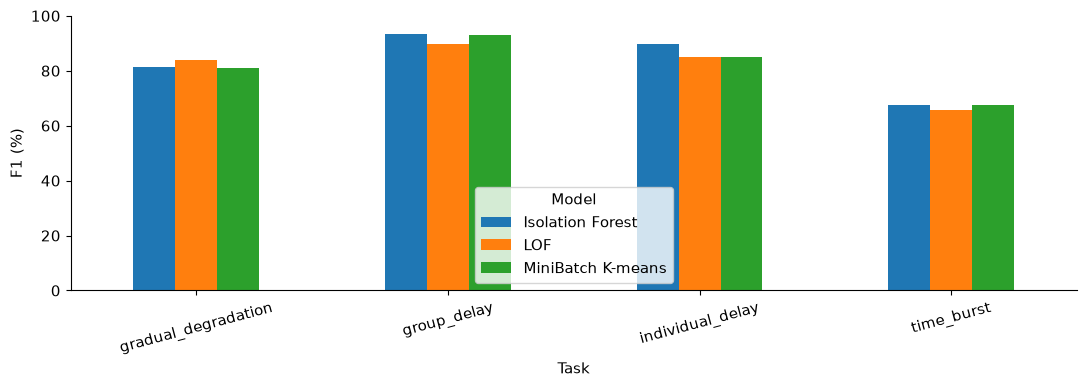

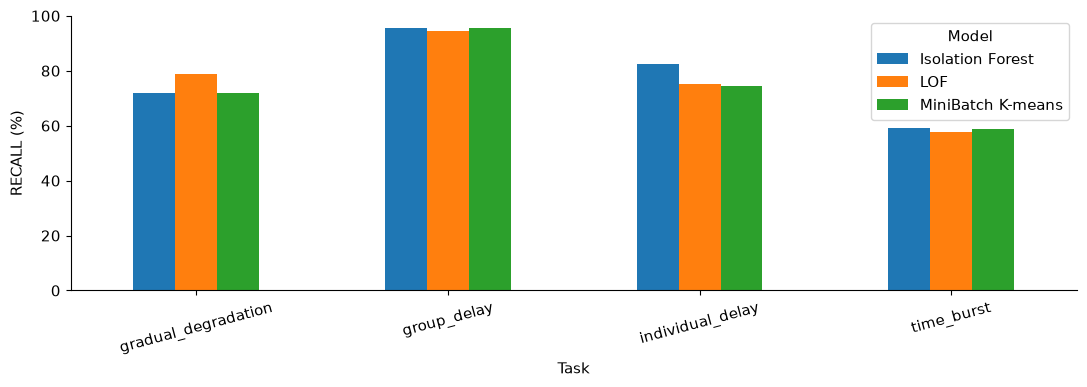

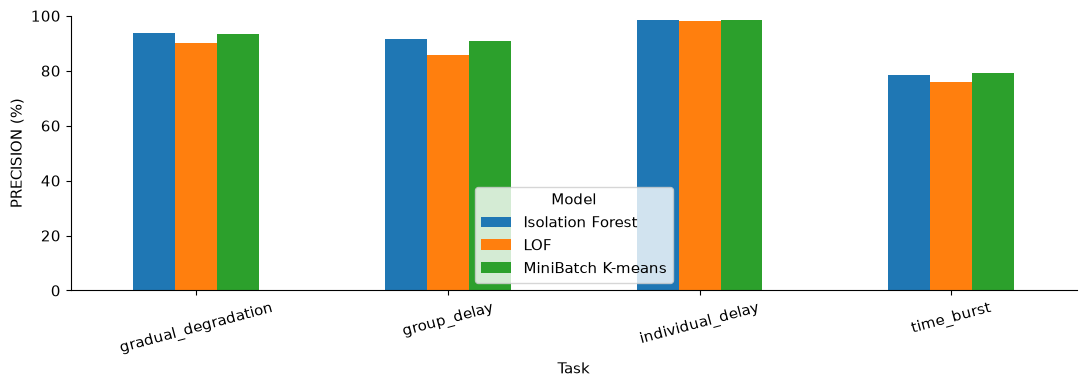

In [3]:
rows=[{'Task':t,'Model':NAMES[a],**{k:100*r[k] for k in KEYS},'FPR':100*r['false_positive_rate']} for t,d in report['tasks'].items() for a,r in d['current'].items()]
display(pd.DataFrame(rows).round(2))
for metric in ['f1','recall','precision']:
    pd.DataFrame(rows).pivot(index='Task',columns='Model',values=metric).plot.bar(figsize=(11,4),rot=15,ylim=(0,100))
    plt.ylabel(metric.upper()+' (%)');plt.tight_layout();plt.show()


## 3. 해석

IF는 개별 지연 F1이 가장 높고, LOF는 점진적 악화 F1이 가장 높습니다. 집단 지연은 이번 결과에서 IF가 K-means보다 조금 높으므로 K-means가 반드시 최고라고 표현하지 않습니다. 시간대 폭주는 세 모델 모두 상대적으로 어렵고 Precision 손실이 남았습니다.

## 동일한 기준의 직전·최신 비교

같은 4개 시나리오·확인 사례·분 정답으로 계산한 F1입니다. 학습 입력은 달라도 비교 지표의 단위는 같습니다.

,Task,Model,Previous F1,Latest F1,Change (pp)
0,individual_delay,Isolation Forest,87.51,89.88,2.37
1,individual_delay,MiniBatch K-means,80.01,84.90,4.90
2,individual_delay,LOF,83.05,85.08,2.03
3,group_delay,Isolation Forest,89.71,93.51,3.80
4,group_delay,MiniBatch K-means,92.90,93.17,0.28
5,group_delay,LOF,89.54,89.82,0.28
6,time_burst,Isolation Forest,66.78,67.38,0.60
7,time_burst,MiniBatch K-means,67.74,67.43,-0.32
8,time_burst,LOF,67.02,65.67,-1.34
9,gradual_degradation,Isolation Forest,78.03,81.35,3.32


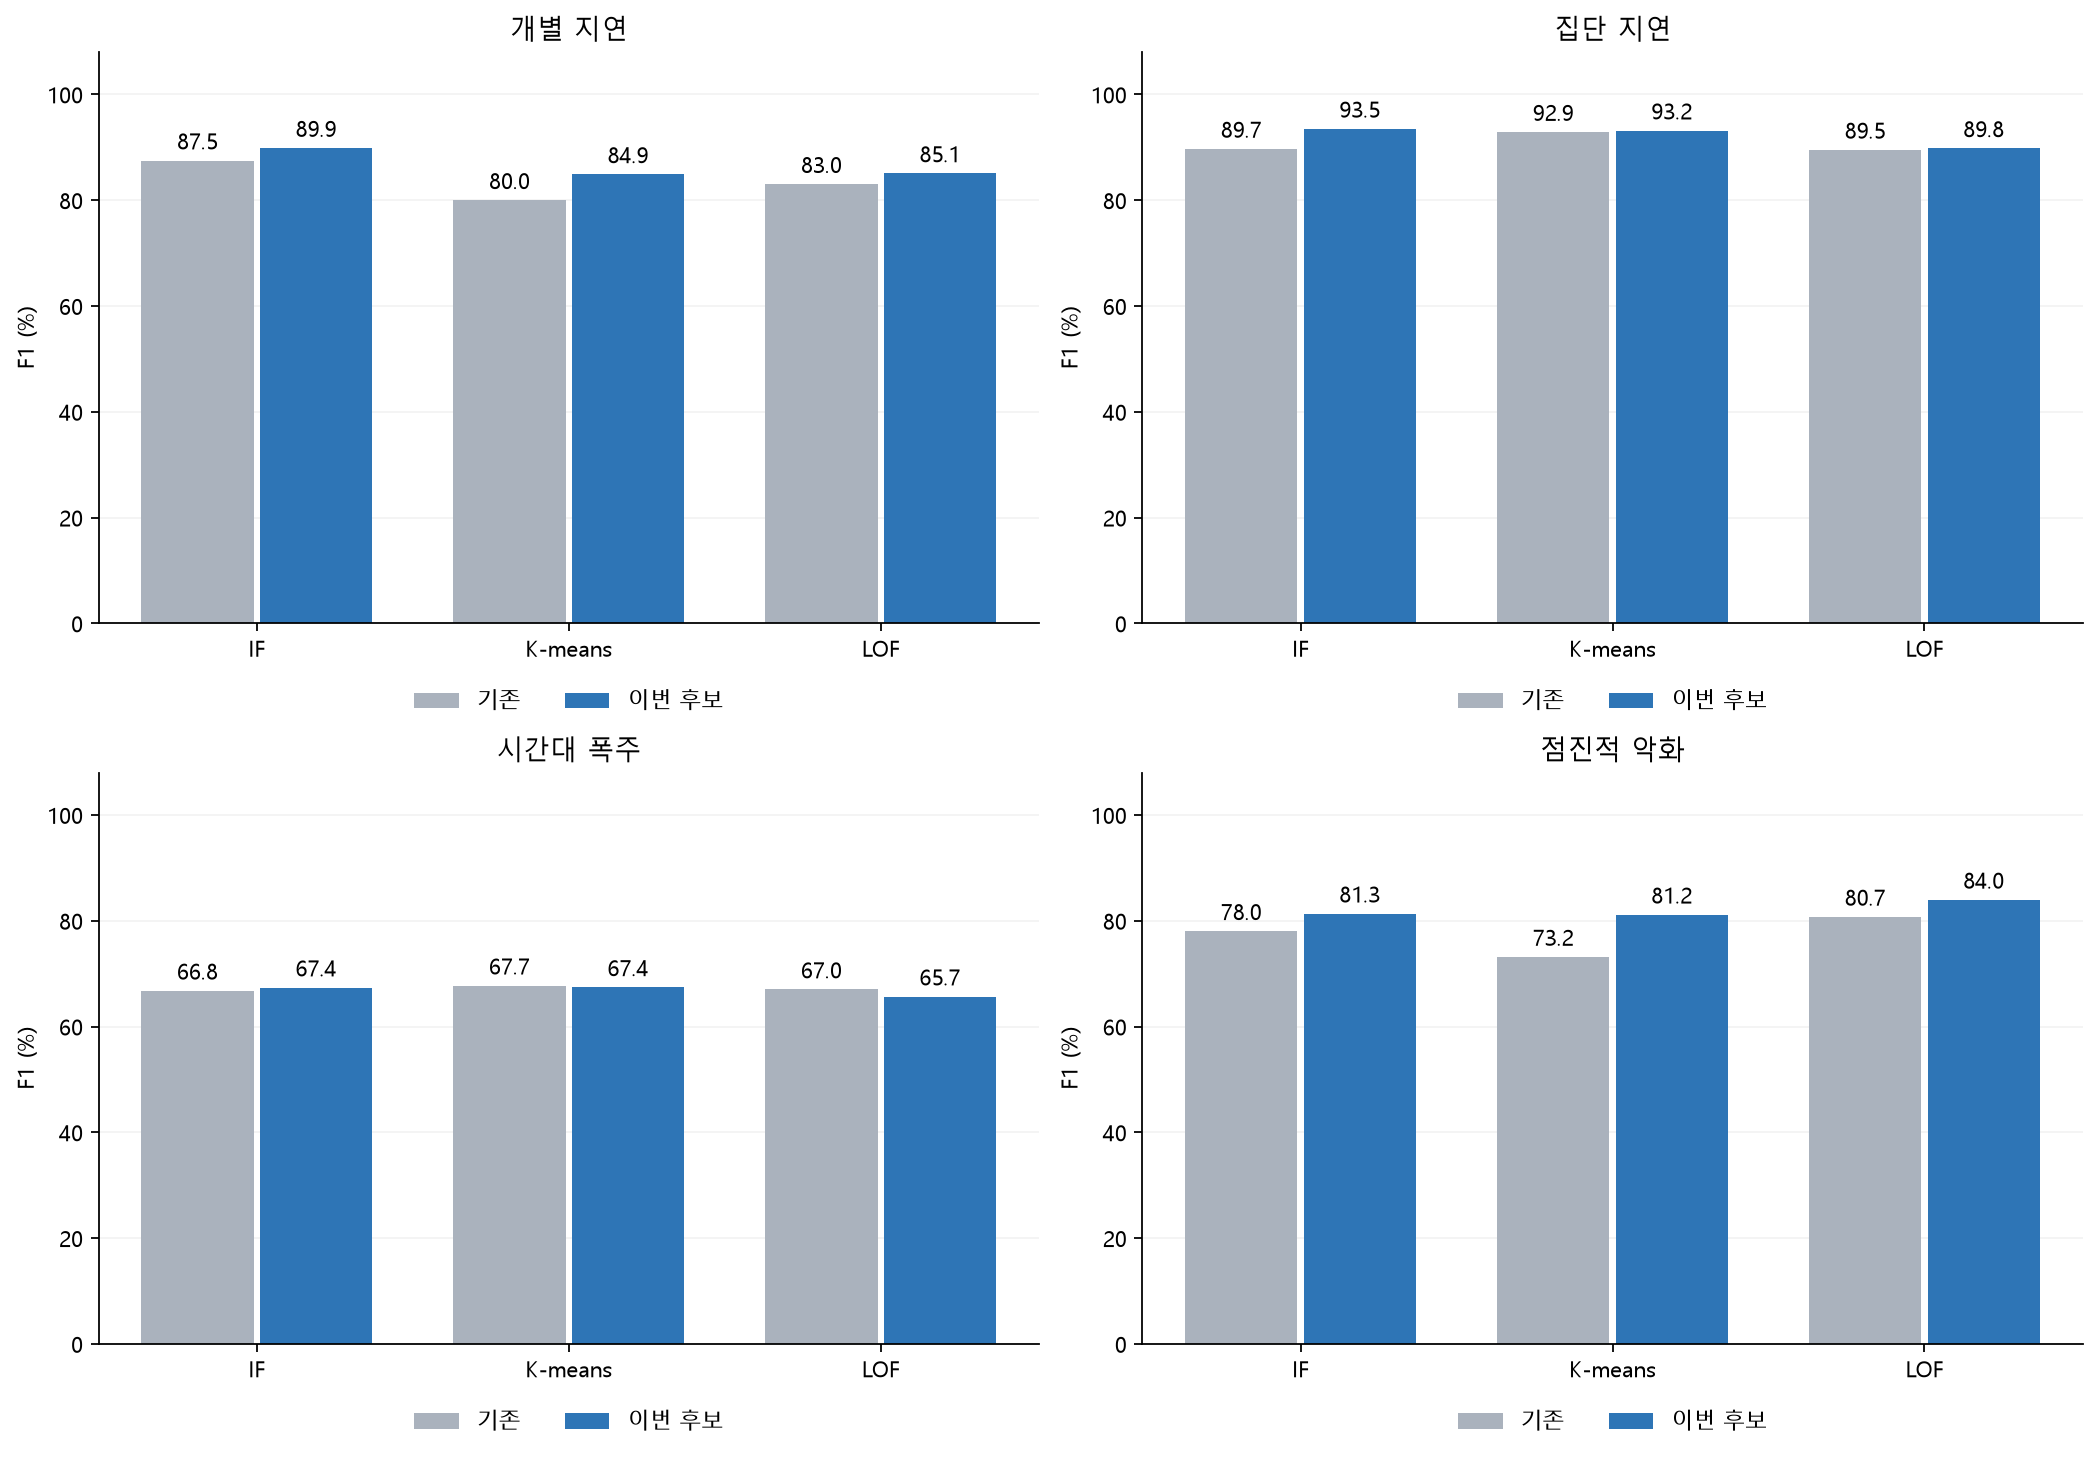

In [4]:
r=read('results/latest/minute_confirmation.json')
comparison=pd.DataFrame([{'Task':t,'Model':NAMES[a],'Previous F1':100*d['legacy'][a]['f1'],'Latest F1':100*d['current'][a]['f1'],'Change (pp)':d['delta_percentage_points'][a]['f1']} for t,d in r['tasks'].items() for a in NAMES])
display(comparison.round(2))
display(Image(filename=str(ROOT/'results/latest/same_minute_f1_comparison.png')))


## 학습・再現上の注意

원본 정상 후보로 sklearn 추정기를 학습했고, 최신의 추가 요일·시간대 건수 참조에는 기존 합성 개발 정상 대조군을 사용했습니다. 설정·경보 기준 선택에 개발 정답을 사용했습니다. 정상-only 재학습 baseline은 이 보정 전체나 공개 성능을 상속하지 않습니다. 자세한 입력·실행·제약은 README.md, REPRODUCING.md, MODEL_COMPARISON.md를 확인하십시오.

이 노트북은 포함된 집계 결과만 읽습니다. 원본 CSV·벤치마크·개발 캐시 없이 실행되지만 모델을 재평가하는 것은 아닙니다.

## 실행별 점수 분포 — 개발 집단

저장된 개발 Process 점수 분포입니다. 확인 집단 성능표와 혼동하지 않습니다. 경보선은 확률이 아닌 정규화 점수 1입니다.

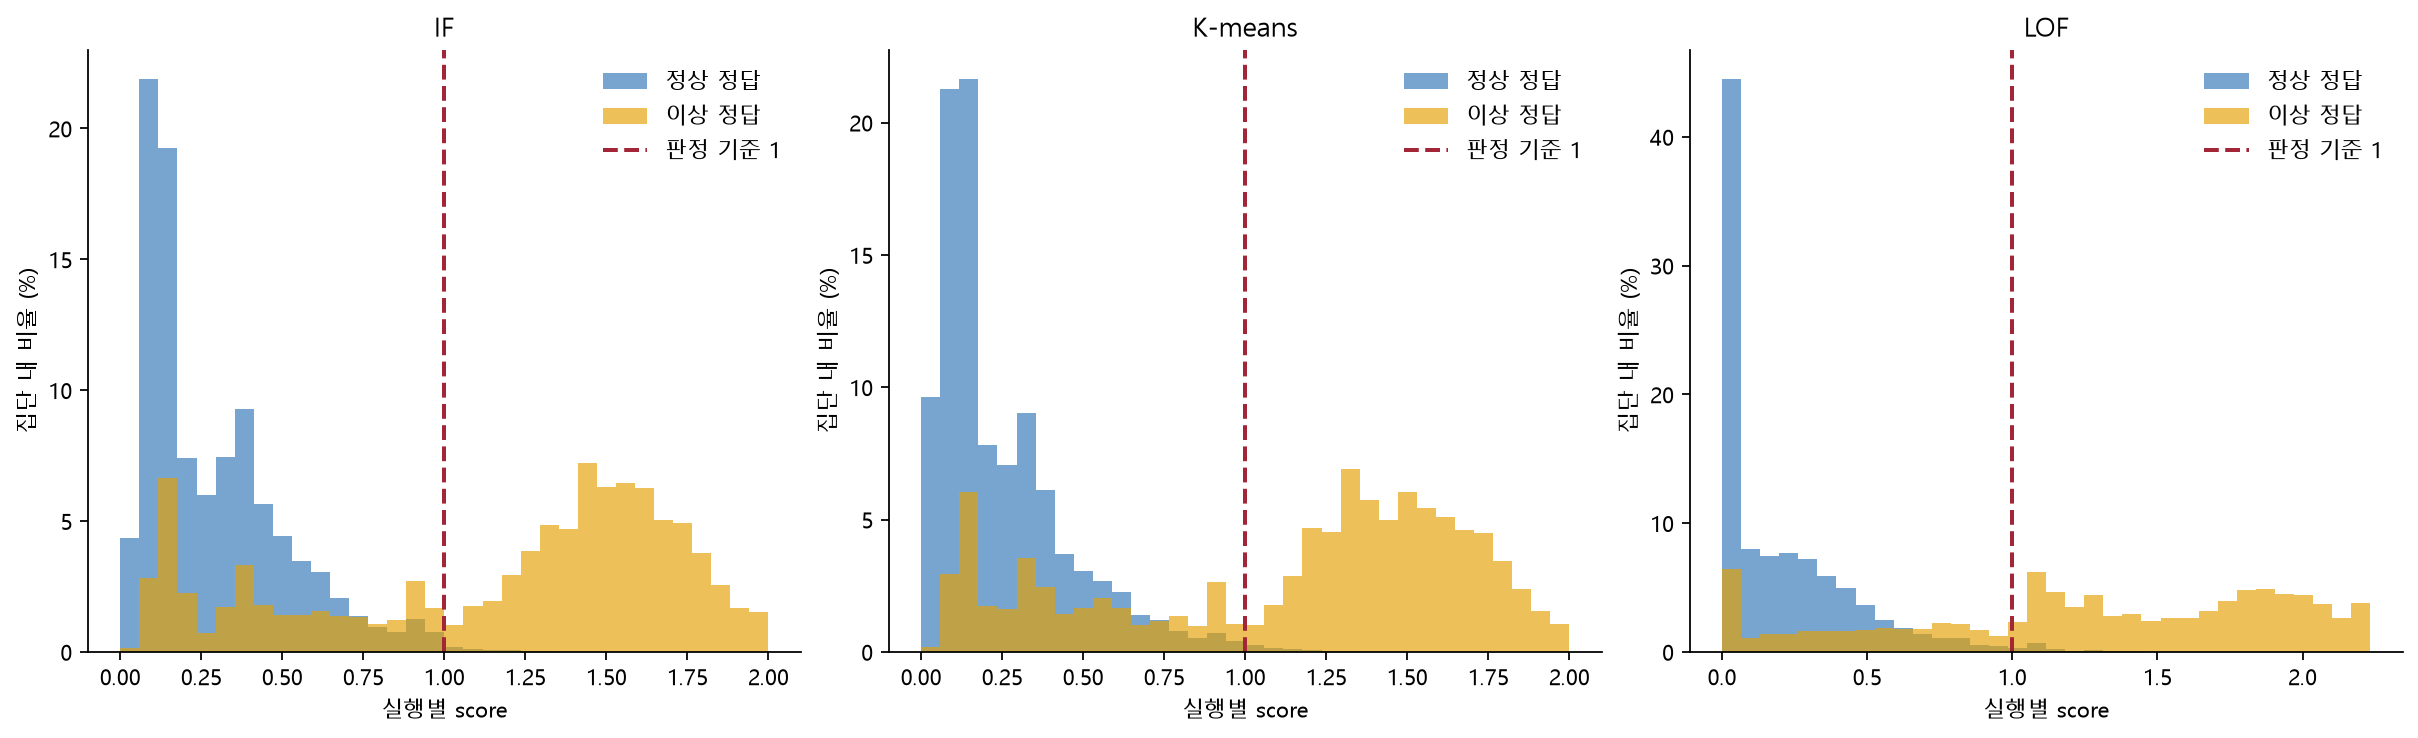

In [5]:
display(Image(filename=str(ROOT/'results/latest/development_Process_score_distribution.png')))